# Quantization

**Idea:** store the network's weights as small 8-bit integers instead of 32-bit decimals, to save space and maybe time.

In [1]:
import os, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# Fix the random seed so results are repeatable
torch.manual_seed(42)
np.random.seed(42)

# Folders for the dataset and for saved results
from google.colab import drive
drive.mount("/content/drive")
os.chdir("/content/drive/MyDrive")  # data/ and outputs/ will now be created here
os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("PyTorch version:", torch.__version__)

Mounted at /content/drive
PyTorch version: 2.11.0+cpu


In [2]:
# Fashion-MNIST: 28x28 grayscale pictures of clothes, 10 classes
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.286,), (0.353,))])
full_train = datasets.FashionMNIST("data", train=True, download=True, transform=transform)
test_data = datasets.FashionMNIST("data", train=False, download=True, transform=transform)

# Shuffle once, then use 12,000 images for training and 3,000 for validation
idx = np.random.permutation(len(full_train))
train_data = Subset(full_train, idx[:12000].tolist())
val_data = Subset(full_train, idx[12000:15000].tolist())

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=64)
test_loader = DataLoader(test_data, batch_size=64)
print("train / val / test sizes:", len(train_data), len(val_data), len(test_data))

train / val / test sizes: 12000 3000 10000


In [3]:
# A simple neural network: 784 pixels -> 256 -> 128 -> 10 classes
class MLP(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.layers(x)

In [4]:
loss_fn = nn.CrossEntropyLoss()

def evaluate(model, loader):
    """Return (average loss, accuracy) of the model on a dataset."""
    model.eval()
    correct, total, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for x, y in loader:
            out = model(x)
            loss_sum += loss_fn(out, y).item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
    return loss_sum / total, correct / total

def train(model, loader, epochs=3, lr=1e-3, weight_decay=0.0, make_scheduler=None):
    """Train with Adam. Returns a table of per-epoch results and the training time."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = make_scheduler(optimizer) if make_scheduler else None
    history = []
    start = time.time()
    for epoch in range(epochs):
        model.train()
        loss_sum, seen = 0.0, 0
        for x, y in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
            seen += len(y)
        val_loss, val_acc = evaluate(model, val_loader)
        history.append({"epoch": epoch + 1, "train_loss": loss_sum / seen, "val_loss": val_loss,
                        "val_acc": val_acc, "lr": optimizer.param_groups[0]["lr"]})
        print(f"epoch {epoch+1}/{epochs}  train_loss={loss_sum/seen:.4f}  val_loss={val_loss:.4f}  val_acc={val_acc:.4f}")
        if scheduler:
            scheduler.step()
    return pd.DataFrame(history), time.time() - start

## Step 1: Train the normal (FP32) model

In [5]:
model = MLP()
history, secs = train(model, train_loader)
model.eval()

epoch 1/3  train_loss=0.6612  val_loss=0.4516  val_acc=0.8360
epoch 2/3  train_loss=0.4411  val_loss=0.4100  val_acc=0.8507
epoch 3/3  train_loss=0.3853  val_loss=0.3901  val_acc=0.8580


MLP(
  (layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.0, inplace=False)
    (7): Linear(in_features=128, out_features=10, bias=True)
  )
)

## Step 2: Quantize it

Dynamic quantization converts the `Linear` layers to INT8.

In [6]:
quantized = torch.ao.quantization.quantize_dynamic(model, {nn.Linear}, dtype=torch.qint8)
quantized.eval()

# Save both so we can compare file sizes
torch.save(model.state_dict(), "outputs/fp32.pt")
torch.save(quantized.state_dict(), "outputs/int8.pt")
size_fp32 = os.path.getsize("outputs/fp32.pt") / 1e6
size_int8 = os.path.getsize("outputs/int8.pt") / 1e6
print(f"FP32: {size_fp32:.3f} MB   INT8: {size_int8:.3f} MB")

/tmp/ipykernel_4436/1109070255.py:1: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quantized = torch.ao.quantization.quantize_dynamic(model, {nn.Linear}, dtype=torch.qint8)


FP32: 0.943 MB   INT8: 0.241 MB


## Step 3: Compare accuracy and speed

In [7]:
def time_per_batch(model, repeats=5, n_batches=20):
    """Average milliseconds to run one batch (median over several repeats)."""
    batches = []
    for i, (x, y) in enumerate(test_loader):
        if i >= n_batches:
            break
        batches.append(x)
    times = []
    with torch.no_grad():
        for _ in range(repeats):
            start = time.time()
            for x in batches:
                model(x)
            times.append((time.time() - start) / len(batches) * 1000)
    return float(np.median(times))

rows = []
for name, m, size in [("FP32", model, size_fp32), ("INT8", quantized, size_int8)]:
    test_loss, test_acc = evaluate(m, test_loader)
    rows.append({"model": name, "test_accuracy": test_acc, "size_MB": size,
                 "ms_per_batch": time_per_batch(m)})

results = pd.DataFrame(rows)
results.to_csv("outputs/quantization_results.csv", index=False)
print(results)

  model  test_accuracy   size_MB  ms_per_batch
0  FP32         0.8419  0.943345      0.440812
1  INT8         0.8416  0.241097      0.336969


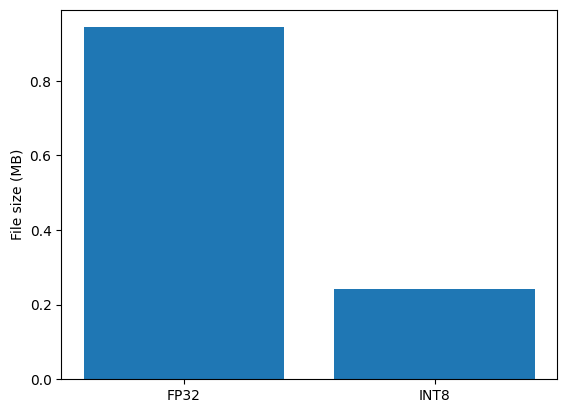

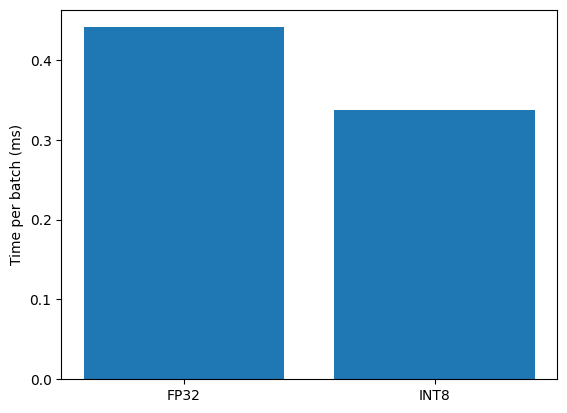

In [8]:
plt.bar(results["model"], results["size_MB"])
plt.ylabel("File size (MB)")
plt.savefig('outputs/file_size.png')
plt.show()

plt.bar(results["model"], results["ms_per_batch"])
plt.ylabel("Time per batch (ms)")
plt.savefig('outputs/quantization_latenty.png')

plt.show()